# African Logistics Intelligence
## Phase 5.6: Travel-Time Prediction (Clean Notebook)

**Purpose:** build and evaluate a travel-time prediction pipeline using the existing Lagos OSM road network and the project's hourly weather dataset.

### Important modelling limitation
The current target, `estimated_travel_time_min`, is generated by a project-defined formula using road class, road length, time-of-day and precipitation. It is **synthetic**, not observed vehicle travel time. This notebook can test the data pipeline and whether ML models reproduce that formula. It cannot establish real-world Lagos travel-time accuracy.

The exact rule-based calculation is therefore included as a benchmark. If it produces zero error, that is expected because it generated the target.

### Notebook structure
1. Setup and source-data checks
2. Road features and geographically distributed sample
3. Build the expanded synthetic dataset
4. Train and evaluate models
5. Save the model and prepare for later integration

The OSM network is reused from Phase 5.3. This notebook does not download the road network again.

## Section 1 of 5: Setup and source-data checks

In [1]:
# CELL 1.1: IMPORTS, PROJECT PATHS AND OUTPUT DIRECTORIES

# If a package is missing, run this once in a separate cell:
# %pip install pandas numpy geopandas osmnx scikit-learn xgboost pyarrow joblib matplotlib

from pathlib import Path
import ast
import warnings

import numpy as np
import pandas as pd
import geopandas as gpd
import osmnx as ox
import pyarrow as pa
import pyarrow.parquet as pq

from sklearn.model_selection import GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.base import clone
import joblib
import matplotlib.pyplot as plt

try:
    from xgboost import XGBRegressor
except ImportError:
    XGBRegressor = None
    print("XGBoost is not installed. Random Forest will still run.")

warnings.filterwarnings("ignore", category=FutureWarning)

# Find the project root using a file that already exists in the project.
PROJECT_ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / "data" / "raw" / "scenario.csv").exists()),
    None
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate the project root. Open this notebook inside "
        "the ALI project folder or update PROJECT_ROOT manually."
    )

NETWORK_DIR = PROJECT_ROOT / "data" / "processed" / "phase5_network"
WEATHER_DIR = PROJECT_ROOT / "data" / "raw" / "external" / "weather"
DATASET_DIR = PROJECT_ROOT / "data" / "processed" / "phase5_dataset"
MODEL_DIR = PROJECT_ROOT / "models"

for folder in [DATASET_DIR, MODEL_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

EDGES_PATH = NETWORK_DIR / "osm_edges.geojson"
GRAPH_PATH = NETWORK_DIR / "osm_road_network.graphml"
WEATHER_PATH = WEATHER_DIR / "lagos_hourly_weather.csv"

print("Project root:", PROJECT_ROOT)
print("OSM edges available:", EDGES_PATH.exists())
print("OSM graph available:", GRAPH_PATH.exists())
print("Weather file available:", WEATHER_PATH.exists())

Project root: C:\Users\ginik\Documents\CODING\Portfolio-projects\Project-2-African-Logistics-Intelligence\african-logistics-intelligence-start
OSM edges available: True
OSM graph available: True
Weather file available: True


In [2]:
# CELL 1.2: LOAD AND CHECK THE EXISTING WEATHER DATA

if not WEATHER_PATH.exists():
    raise FileNotFoundError(
        f"Weather file not found: {WEATHER_PATH}. "
        "The expected file is data/raw/external/weather/lagos_hourly_weather.csv."
    )

weather_hourly = pd.read_csv(WEATHER_PATH)
weather_hourly["time"] = pd.to_datetime(
    weather_hourly["time"],
    errors="coerce"
)

WEATHER_COLUMNS = [
    "temperature_2m",
    "relative_humidity_2m",
    "precipitation",
    "rain",
    "wind_speed_10m",
    "weather_code"
]

required_weather = ["time"] + WEATHER_COLUMNS
missing = [c for c in required_weather if c not in weather_hourly.columns]

if missing:
    raise KeyError(f"Missing weather columns: {missing}")

weather_hourly = (
    weather_hourly[required_weather]
    .dropna(subset=["time"])
    .sort_values("time")
    .reset_index(drop=True)
)

if weather_hourly["time"].duplicated().any():
    raise ValueError("Weather data contains duplicate timestamps.")

if weather_hourly[WEATHER_COLUMNS].isna().all(axis=1).any():
    raise ValueError("At least one weather timestamp has no weather values.")

print("Weather records:", len(weather_hourly))
print("Time range:", weather_hourly["time"].min(), "to", weather_hourly["time"].max())
print("\nMissing weather values:")
print(weather_hourly.isna().sum())

Weather records: 720
Time range: 2025-01-01 00:00:00 to 2025-01-30 23:00:00

Missing weather values:
time                    0
temperature_2m          0
relative_humidity_2m    0
precipitation           0
rain                    0
wind_speed_10m          0
weather_code            0
dtype: int64


## Section 2 of 5: Road features and 5,000-road sample

In [3]:
# CELL 2.1: LOAD THE EXISTING OSM ROAD NETWORK

if not EDGES_PATH.exists() or not GRAPH_PATH.exists():
    raise FileNotFoundError(
        "The Phase 5.3 OSM GeoJSON or GraphML file is missing."
    )

edges_gdf = gpd.read_file(EDGES_PATH)
G = ox.load_graphml(GRAPH_PATH)

if edges_gdf.crs is None:
    raise ValueError("The OSM edge GeoDataFrame has no CRS.")

required_edge_columns = {"u", "v", "key", "geometry"}
missing = required_edge_columns - set(edges_gdf.columns)

if missing:
    raise KeyError(f"Missing required OSM edge columns: {sorted(missing)}")

highway_column = (
    "highway_value" if "highway_value" in edges_gdf.columns
    else "highway" if "highway" in edges_gdf.columns
    else None
)

if highway_column is None:
    raise KeyError("No highway or highway_value column exists.")

print("Graph nodes:", len(G.nodes))
print("Graph edges:", len(G.edges))
print("GeoJSON edge records:", len(edges_gdf))
print("CRS:", edges_gdf.crs)
print("\nRoad-class values:")
print(edges_gdf[highway_column].value_counts(dropna=False).head(25))

C:\Users\ginik\Documents\CODING\Portfolio-projects\Project-2-African-Logistics-Intelligence\african-logistics-intelligence-start\.venv\Lib\site-packages\geopandas\io\file.py:582: UserWarning: Could not parse column 'reversed' as JSON; leaving as string
  return pyogrio.read_dataframe(path_or_bytes, bbox=bbox, **kwargs)


Graph nodes: 98859
Graph edges: 241018
GeoJSON edge records: 241018
CRS: EPSG:4326

Road-class values:
highway_value
residential       206498
tertiary           11602
unclassified       10311
secondary           5400
primary             3721
trunk               1798
motorway_link        329
trunk_link           310
motorway             275
primary_link         270
secondary_link       215
tertiary_link        171
living_street         56
busway                56
undefined              6
Name: count, dtype: int64


In [4]:
# CELL 2.2: ENGINEER ROAD-SEGMENT FEATURES

def first_osm_value(value):
    # OSM tags can be scalar values or lists.
    if value is None:
        return None
    if isinstance(value, (list, tuple)):
        return str(value[0]).strip().lower() if value else None
    if pd.api.types.is_scalar(value) and pd.isna(value):
        return None

    text = str(value).strip()
    if not text:
        return None

    if text.startswith("["):
        try:
            parsed = ast.literal_eval(text)
            if isinstance(parsed, (list, tuple)):
                return str(parsed[0]).strip().lower() if parsed else None
        except (ValueError, SyntaxError):
            pass

    return text.lower()


def tag_is_present(value):
    if value is None:
        return 0
    if isinstance(value, (list, tuple)):
        return int(any(str(v).strip() for v in value))
    if pd.api.types.is_scalar(value) and pd.isna(value):
        return 0
    return int(str(value).strip().lower() not in {"", "nan", "none", "[]"})


def tag_is_affirmative(value):
    return int(first_osm_value(value) in {"yes", "true", "1"})


def normalize_node_id(value):
    # Handles IDs that may have been read as integers, strings or floats.
    try:
        number = float(value)
        if number.is_integer():
            return str(int(number))
    except (TypeError, ValueError):
        pass
    return str(value)


# The current synthetic speed rules are defined for these six classes only.
BASE_SPEEDS = {
    "motorway": 70,
    "trunk": 60,
    "primary": 45,
    "secondary": 35,
    "tertiary": 30,
    "residential": 20
}

edges_gdf = edges_gdf.copy()
edges_gdf["road_class"] = edges_gdf[highway_column].apply(first_osm_value)
edges_gdf = edges_gdf[
    edges_gdf["road_class"].isin(BASE_SPEEDS)
].copy()

if edges_gdf.empty:
    raise ValueError("No road edges remain in the six supported road classes.")

# Road length in kilometres.
if "length_km" not in edges_gdf.columns:
    if "length" not in edges_gdf.columns:
        raise KeyError("Neither length_km nor length exists in the OSM data.")
    edges_gdf["length_km"] = pd.to_numeric(
        edges_gdf["length"], errors="coerce"
    ) / 1000
else:
    edges_gdf["length_km"] = pd.to_numeric(
        edges_gdf["length_km"], errors="coerce"
    )

# Midpoint coordinates: calculate in a projected CRS, then convert to WGS84.
projected_crs = edges_gdf.estimate_utm_crs()
if projected_crs is None:
    raise ValueError("Could not estimate a projected CRS for the road network.")

edges_projected = edges_gdf.to_crs(projected_crs)
midpoints_projected = edges_projected.geometry.interpolate(
    0.5, normalized=True
)
midpoints_wgs84 = gpd.GeoSeries(
    midpoints_projected, crs=projected_crs
).to_crs("EPSG:4326")

edges_gdf["longitude"] = midpoints_wgs84.x.to_numpy()
edges_gdf["latitude"] = midpoints_wgs84.y.to_numpy()

# Count unique neighbouring nodes, avoiding successor/predecessor double-counting.
node_degree = {
    normalize_node_id(node):
        len(set(G.successors(node)) | set(G.predecessors(node)))
    for node in G.nodes
}

edges_gdf["u_id"] = edges_gdf["u"].apply(normalize_node_id)
edges_gdf["v_id"] = edges_gdf["v"].apply(normalize_node_id)

edges_gdf["u_degree"] = edges_gdf["u_id"].map(node_degree).fillna(0).astype("int32")
edges_gdf["v_degree"] = edges_gdf["v_id"].map(node_degree).fillna(0).astype("int32")

edges_gdf["u_is_junction"] = (edges_gdf["u_degree"] > 2).astype("int8")
edges_gdf["v_is_junction"] = (edges_gdf["v_degree"] > 2).astype("int8")
edges_gdf["endpoint_junction_count"] = (
    edges_gdf["u_is_junction"] + edges_gdf["v_is_junction"]
).astype("int8")

edges_gdf["mean_endpoint_degree"] = (
    edges_gdf["u_degree"] + edges_gdf["v_degree"]
) / 2
edges_gdf["max_endpoint_degree"] = edges_gdf[
    ["u_degree", "v_degree"]
].max(axis=1)
edges_gdf["min_endpoint_degree"] = edges_gdf[
    ["u_degree", "v_degree"]
].min(axis=1)

# One-way status: -1 is also one-way, but in the reverse direction.
oneway_col = "oneway_value" if "oneway_value" in edges_gdf.columns else "oneway"
oneway_raw = (
    edges_gdf[oneway_col].apply(first_osm_value)
    if oneway_col in edges_gdf.columns
    else pd.Series(index=edges_gdf.index, dtype="object")
)
edges_gdf["is_oneway"] = oneway_raw.map({
    "yes": 1, "true": 1, "1": 1, "-1": 1,
    "no": 0, "false": 0, "0": 0
})

def source_column(name):
    candidates = [f"{name}_value", name]
    for candidate in candidates:
        if candidate in edges_gdf.columns:
            return edges_gdf[candidate]
    return pd.Series(np.nan, index=edges_gdf.index)

edges_gdf["has_bridge"] = source_column("bridge").apply(tag_is_affirmative)
edges_gdf["has_tunnel"] = source_column("tunnel").apply(tag_is_affirmative)
edges_gdf["has_maxspeed"] = source_column("maxspeed").apply(tag_is_present)
edges_gdf["has_lanes"] = source_column("lanes").apply(tag_is_present)
edges_gdf["has_name"] = source_column("name").apply(tag_is_present)
edges_gdf["has_access"] = source_column("access").apply(tag_is_present)

edges_gdf["road_segment_id"] = (
    edges_gdf["u_id"] + "_" +
    edges_gdf["v_id"] + "_" +
    edges_gdf["key"].astype(str)
)

feature_columns = [
    "road_segment_id", "road_class", "length_km",
    "latitude", "longitude", "is_oneway",
    "has_bridge", "has_tunnel", "has_maxspeed",
    "has_lanes", "has_name", "has_access",
    "u_degree", "v_degree", "u_is_junction", "v_is_junction",
    "endpoint_junction_count", "mean_endpoint_degree",
    "max_endpoint_degree", "min_endpoint_degree"
]

road_features = edges_gdf[feature_columns].copy()
road_features = road_features.dropna(
    subset=["road_segment_id", "road_class", "length_km", "latitude", "longitude"]
)
road_features = road_features[
    (road_features["length_km"] > 0)
    & road_features["latitude"].between(-90, 90)
    & road_features["longitude"].between(-180, 180)
].copy()

if road_features["road_segment_id"].duplicated().any():
    raise ValueError("Duplicate road segment IDs exist. Inspect OSM edge identifiers.")

print("Eligible road segments:", len(road_features))
print("\nRoad-class distribution:")
print(road_features["road_class"].value_counts())
print("\nFeature preview:")
display(road_features.head())

Eligible road segments: 229294

Road-class distribution:
road_class
residential    206498
tertiary        11602
secondary        5400
primary          3721
trunk            1798
motorway          275
Name: count, dtype: int64

Feature preview:


,road_segment_id,road_class,length_km,latitude,longitude,is_oneway,has_bridge,has_tunnel,has_maxspeed,has_lanes,has_name,has_access,u_degree,v_degree,u_is_junction,v_is_junction,endpoint_junction_count,mean_endpoint_degree,max_endpoint_degree,min_endpoint_degree
0,3202618256_10175580642_0,residential,0.275258,6.399850,4.266696,0,0,0,0,0,0,0,3,3,1,1,2,3.0,3,3
3,3202618257_10175580617_0,residential,0.128581,6.399009,4.269427,0,0,0,0,0,0,0,4,4,1,1,2,4.0,4,4
7,3202622663_6622846681_0,secondary,0.062257,6.415196,4.095017,0,0,0,0,0,1,0,3,3,1,1,2,3.0,3,3
8,3202622663_12114539856_0,residential,0.243173,6.414389,4.094181,0,0,0,0,0,0,0,3,1,1,0,1,2.0,3,1
9,3202622663_3202622665_0,secondary,0.161850,6.415599,4.094088,0,0,0,0,0,1,0,3,3,1,1,2,3.0,3,3


In [5]:
# CELL 2.3: SELECT 5,000 ROADS BY ROAD CLASS AND GEOGRAPHIC GRID

SAMPLE_SIZE = 5000
GRID_SIZE_DEGREES = 0.05
RANDOM_STATE = 42

if len(road_features) < SAMPLE_SIZE:
    raise ValueError(
        f"Only {len(road_features)} eligible roads are available; "
        f"{SAMPLE_SIZE} were requested."
    )

sampling_frame = road_features.copy()
sampling_frame["grid_lat"] = (
    np.floor(sampling_frame["latitude"] / GRID_SIZE_DEGREES)
    * GRID_SIZE_DEGREES
)
sampling_frame["grid_lon"] = (
    np.floor(sampling_frame["longitude"] / GRID_SIZE_DEGREES)
    * GRID_SIZE_DEGREES
)

strata = ["road_class", "grid_lat", "grid_lon"]
strata_sizes = (
    sampling_frame.groupby(strata, observed=True)
    .size()
    .rename("population")
    .reset_index()
)

# Proportional allocation, rounded with the largest-remainder method.
strata_sizes["exact_quota"] = (
    strata_sizes["population"] / len(sampling_frame) * SAMPLE_SIZE
)
strata_sizes["quota"] = np.floor(
    strata_sizes["exact_quota"]
).astype(int)

remaining = SAMPLE_SIZE - int(strata_sizes["quota"].sum())
strata_sizes["remainder"] = (
    strata_sizes["exact_quota"] - strata_sizes["quota"]
)
strata_sizes = strata_sizes.sort_values(
    "remainder", ascending=False
).reset_index(drop=True)

if remaining > 0:
    strata_sizes.loc[strata_sizes.index[:remaining], "quota"] += 1

quota_lookup = {
    (row.road_class, row.grid_lat, row.grid_lon): int(row.quota)
    for row in strata_sizes.itertuples(index=False)
}

sample_parts = []
for group_key, group in sampling_frame.groupby(
    strata, observed=True, sort=False
):
    quota = quota_lookup[group_key]
    if quota:
        sample_parts.append(
            group.sample(n=quota, replace=False, random_state=RANDOM_STATE)
        )

road_sample_5000 = pd.concat(sample_parts, ignore_index=True)
road_sample_5000 = road_sample_5000.drop(
    columns=["grid_lat", "grid_lon"]
)

if len(road_sample_5000) != SAMPLE_SIZE:
    raise ValueError(
        f"Expected {SAMPLE_SIZE} sampled roads; got {len(road_sample_5000)}."
    )

if road_sample_5000["road_segment_id"].nunique() != SAMPLE_SIZE:
    raise ValueError("The 5,000-road sample contains duplicate road IDs.")

print("Sample size:", len(road_sample_5000))
print("\nSampled road classes:")
print(road_sample_5000["road_class"].value_counts())
print("\nLatitude range:",
      road_sample_5000["latitude"].min(),
      "to", road_sample_5000["latitude"].max())
print("Longitude range:",
      road_sample_5000["longitude"].min(),
      "to", road_sample_5000["longitude"].max())

Sample size: 5000

Sampled road classes:
road_class
residential    4503
tertiary        256
secondary       117
primary          80
trunk            39
motorway          5
Name: count, dtype: int64

Latitude range: 6.376963147673434 to 6.691971939961591
Longitude range: 2.7065688141973907 to 4.333034149999115


In [6]:
# CELL 2.4: SAVE THE ROAD SAMPLE

ROAD_SAMPLE_PATH = DATASET_DIR / "road_sample_5000.parquet"

road_sample_5000.to_parquet(
    ROAD_SAMPLE_PATH,
    index=False,
    compression="snappy"
)

print("Saved:", ROAD_SAMPLE_PATH)
print("Rows:", len(road_sample_5000))
print("Columns:", len(road_sample_5000.columns))

Saved: C:\Users\ginik\Documents\CODING\Portfolio-projects\Project-2-African-Logistics-Intelligence\african-logistics-intelligence-start\data\processed\phase5_dataset\road_sample_5000.parquet
Rows: 5000
Columns: 20


## Section 3 of 5: Build the expanded synthetic dataset

In [7]:
# CELL 3.1: PREPARE WEATHER AND TIME FEATURES

weather_hourly = weather_hourly.copy()
weather_hourly["hour"] = weather_hourly["time"].dt.hour
weather_hourly["day_of_week"] = weather_hourly["time"].dt.dayofweek
weather_hourly["is_weekend"] = (
    weather_hourly["day_of_week"] >= 5
).astype("int8")

# The original experiment used 30 days of hourly weather (720 records).
print("Weather rows:", len(weather_hourly))
print("Unique timestamps:", weather_hourly["time"].nunique())
print("Hourly gaps:", weather_hourly["time"].diff().dropna().value_counts().head())

if weather_hourly["time"].nunique() != len(weather_hourly):
    raise ValueError("Weather timestamps are not unique.")

Weather rows: 720
Unique timestamps: 720
Hourly gaps: time
0 days 01:00:00    719
Name: count, dtype: int64


In [8]:
# CELL 3.2: GENERATE ROAD-HOUR RECORDS IN BATCHES AND WRITE PARQUET

# This avoids holding all 3.6 million rows in memory at once.
DATASET_PATH = DATASET_DIR / "ml_data_5000.parquet"
ROADS_PER_BATCH = 250

def build_synthetic_batch(road_batch, weather):
    batch = road_batch.merge(weather, how="cross")

    batch["base_speed_kmh"] = batch["road_class"].map(BASE_SPEEDS)

    hour = batch["hour"]
    batch["time_multiplier"] = np.select(
        [
            hour.between(7, 9),
            hour.between(16, 19),
            hour.between(10, 15),
            hour.between(20, 22)
        ],
        [0.65, 0.60, 0.85, 0.90],
        default=1.0
    )

    precipitation = batch["precipitation"].fillna(0)
    batch["weather_multiplier"] = np.select(
        [
            precipitation >= 5,
            precipitation >= 2,
            precipitation > 0
        ],
        [0.75, 0.85, 0.95],
        default=1.0
    )

    batch["estimated_speed_kmh"] = (
        batch["base_speed_kmh"]
        * batch["time_multiplier"]
        * batch["weather_multiplier"]
    ).clip(lower=5)

    batch["estimated_travel_time_min"] = (
        batch["length_km"]
        / batch["estimated_speed_kmh"]
        * 60
    )

    # Remove intermediate formula components from the saved modelling table.
    return batch.drop(
        columns=["base_speed_kmh", "time_multiplier", "weather_multiplier"]
    )


if DATASET_PATH.exists():
    DATASET_PATH.unlink()

writer = None
schema = None

try:
    for start in range(0, len(road_sample_5000), ROADS_PER_BATCH):
        road_batch = road_sample_5000.iloc[
            start:start + ROADS_PER_BATCH
        ].copy()

        batch_df = build_synthetic_batch(road_batch, weather_hourly)
        table = pa.Table.from_pandas(batch_df, preserve_index=False)

        if writer is None:
            schema = table.schema
            writer = pq.ParquetWriter(
                DATASET_PATH,
                schema,
                compression="snappy"
            )
        else:
            table = table.cast(schema)

        writer.write_table(table)

        print(
            f"Processed roads {start + 1} to "
            f"{start + len(road_batch)}"
        )
finally:
    if writer is not None:
        writer.close()

print("\nDataset created:", DATASET_PATH)

Processed roads 1 to 250
Processed roads 251 to 500
Processed roads 501 to 750
Processed roads 751 to 1000
Processed roads 1001 to 1250
Processed roads 1251 to 1500
Processed roads 1501 to 1750
Processed roads 1751 to 2000
Processed roads 2001 to 2250
Processed roads 2251 to 2500
Processed roads 2501 to 2750
Processed roads 2751 to 3000
Processed roads 3001 to 3250
Processed roads 3251 to 3500
Processed roads 3501 to 3750
Processed roads 3751 to 4000
Processed roads 4001 to 4250
Processed roads 4251 to 4500
Processed roads 4501 to 4750
Processed roads 4751 to 5000

Dataset created: C:\Users\ginik\Documents\CODING\Portfolio-projects\Project-2-African-Logistics-Intelligence\african-logistics-intelligence-start\data\processed\phase5_dataset\ml_data_5000.parquet


In [9]:
# CELL 3.3: VALIDATE THE EXPANDED DATASET

parquet_file = pq.ParquetFile(DATASET_PATH)
expected_rows = len(road_sample_5000) * len(weather_hourly)

print("Dataset rows:", parquet_file.metadata.num_rows)
print("Expected rows:", expected_rows)
print("Parquet row groups:", parquet_file.num_row_groups)
print("Dataset size (MB):", round(DATASET_PATH.stat().st_size / (1024**2), 2))

if parquet_file.metadata.num_rows != expected_rows:
    raise ValueError("The generated row count does not match roads × timestamps.")

print("\nFirst records:")
display(parquet_file.read_row_group(0).slice(0, 5).to_pandas())

Dataset rows: 3600000
Expected rows: 3600000
Parquet row groups: 20
Dataset size (MB): 4.11

First records:


,road_segment_id,road_class,length_km,latitude,longitude,is_oneway,has_bridge,has_tunnel,has_maxspeed,has_lanes,...,relative_humidity_2m,precipitation,rain,wind_speed_10m,weather_code,hour,day_of_week,is_weekend,estimated_speed_kmh,estimated_travel_time_min
0,5805279860_12058821918_0,residential,0.054552,6.412567,4.095076,0,0,0,0,0,...,89,0.0,0.0,7.4,0,0,2,0,20.0,0.163657
1,5805279860_12058821918_0,residential,0.054552,6.412567,4.095076,0,0,0,0,0,...,92,0.0,0.0,7.4,0,1,2,0,20.0,0.163657
2,5805279860_12058821918_0,residential,0.054552,6.412567,4.095076,0,0,0,0,0,...,93,0.0,0.0,7.1,0,2,2,0,20.0,0.163657
3,5805279860_12058821918_0,residential,0.054552,6.412567,4.095076,0,0,0,0,0,...,94,0.0,0.0,5.7,0,3,2,0,20.0,0.163657
4,5805279860_12058821918_0,residential,0.054552,6.412567,4.095076,0,0,0,0,0,...,95,0.0,0.0,5.0,0,4,2,0,20.0,0.163657


## Section 4 of 5: Train and evaluate models

In [10]:
# CELL 4.1: SPLIT BY ROAD AND CREATE A MANAGEABLE TRAINING SAMPLE

# We split by road ID, not by individual row. This prevents the same road
# from appearing in both training and test sets.
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(
        road_sample_5000,
        groups=road_sample_5000["road_segment_id"]
    )
)

train_road_ids = set(
    road_sample_5000.iloc[train_idx]["road_segment_id"]
)
test_road_ids = set(
    road_sample_5000.iloc[test_idx]["road_segment_id"]
)

if train_road_ids & test_road_ids:
    raise ValueError("Road-level train/test overlap detected.")

MODEL_COLUMNS = [
    "road_segment_id",
    "road_class", "length_km", "latitude", "longitude",
    "is_oneway", "has_bridge", "has_tunnel", "has_maxspeed",
    "has_lanes", "has_name", "has_access",
    "u_degree", "v_degree", "u_is_junction", "v_is_junction",
    "endpoint_junction_count", "mean_endpoint_degree",
    "max_endpoint_degree", "min_endpoint_degree",
    "temperature_2m", "relative_humidity_2m", "precipitation",
    "rain", "wind_speed_10m", "weather_code",
    "hour", "day_of_week", "is_weekend",
    "estimated_travel_time_min"
]

# To keep model development practical, use 120 randomly selected hours
# per road in both sets. The complete 720-hour dataset remains saved.
ROWS_PER_ROAD_FOR_MODEL = 120

parquet_file = pq.ParquetFile(DATASET_PATH)
train_parts = []
test_parts = []

for row_group in range(parquet_file.num_row_groups):
    part = parquet_file.read_row_group(
        row_group,
        columns=MODEL_COLUMNS
    ).to_pandas()

    train_part = part[
        part["road_segment_id"].isin(train_road_ids)
    ]
    test_part = part[
        part["road_segment_id"].isin(test_road_ids)
    ]

    if not train_part.empty:
        train_parts.append(
            train_part.groupby(
                "road_segment_id", group_keys=False
            ).sample(
                n=ROWS_PER_ROAD_FOR_MODEL,
                random_state=42
            )
        )

    if not test_part.empty:
        test_parts.append(
            test_part.groupby(
                "road_segment_id", group_keys=False
            ).sample(
                n=ROWS_PER_ROAD_FOR_MODEL,
                random_state=43
            )
        )

train_data = pd.concat(train_parts, ignore_index=True)
test_data = pd.concat(test_parts, ignore_index=True)

print("Training roads:", len(train_road_ids))
print("Testing roads:", len(test_road_ids))
print("Training rows:", len(train_data))
print("Testing rows:", len(test_data))
print("Road overlap:",
      len(set(train_data["road_segment_id"]) &
          set(test_data["road_segment_id"])))

Training roads: 4000
Testing roads: 1000
Training rows: 480000
Testing rows: 120000
Road overlap: 0


In [11]:
# CELL 4.2: DEFINE FEATURES AND PREPROCESSING

TARGET = "estimated_travel_time_min"

CATEGORICAL_FEATURES = ["road_class", "weather_code"]

NUMERIC_FEATURES = [
    "length_km", "latitude", "longitude", "is_oneway",
    "has_bridge", "has_tunnel", "has_maxspeed", "has_lanes",
    "has_name", "has_access",
    "u_degree", "v_degree", "u_is_junction", "v_is_junction",
    "endpoint_junction_count", "mean_endpoint_degree",
    "max_endpoint_degree", "min_endpoint_degree",
    "temperature_2m", "relative_humidity_2m",
    "precipitation", "rain", "wind_speed_10m",
    "hour", "day_of_week", "is_weekend"
]

FEATURES = CATEGORICAL_FEATURES + NUMERIC_FEATURES

X_train = train_data[FEATURES]
y_train = train_data[TARGET]

X_test = test_data[FEATURES]
y_test = test_data[TARGET]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("encoder", OneHotEncoder(handle_unknown="ignore"))
            ]),
            CATEGORICAL_FEATURES
        ),
        (
            "numeric",
            SimpleImputer(strategy="median"),
            NUMERIC_FEATURES
        )
    ],
    remainder="drop"
)

print("Predictor count:", len(FEATURES))
print("Categorical predictors:", CATEGORICAL_FEATURES)
print("Training matrix:", X_train.shape)
print("Testing matrix:", X_test.shape)

Predictor count: 28
Categorical predictors: ['road_class', 'weather_code']
Training matrix: (480000, 28)
Testing matrix: (120000, 28)


In [13]:
# CELL 4.3: TRAIN RANDOM FOREST AND XGBOOST

models = {
    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        min_samples_leaf=2,

        max_features=0.8,
        random_state=42,
        n_jobs=-1
    )
}

if XGBRegressor is not None:
    models["XGBoost"] = XGBRegressor(
        n_estimators=300,
        max_depth=8,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        tree_method="hist",
        random_state=42,
        n_jobs=-1
    )

trained_models = {}

for name, estimator in models.items():
    pipeline = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", estimator)
    ])

    print(f"Training {name}...")
    pipeline.fit(X_train, y_train)
    trained_models[name] = pipeline
    print(f"{name} complete.")

Training Random Forest...
Random Forest complete.
Training XGBoost...
XGBoost complete.


In [14]:
# CELL 4.4: EVALUATE ML MODELS AGAINST THE EXACT RULE-BASED GENERATOR

results = []

for name, model in trained_models.items():
    predictions = model.predict(X_test)
    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2": r2_score(y_test, predictions)
    })

# Recreate the same rule that generated the synthetic target.
base_speed = test_data["road_class"].map(BASE_SPEEDS).to_numpy()
hour = test_data["hour"].to_numpy()
precip = test_data["precipitation"].fillna(0).to_numpy()

time_multiplier = np.select(
    [
        (hour >= 7) & (hour <= 9),
        (hour >= 16) & (hour <= 19),
        (hour >= 10) & (hour <= 15),
        (hour >= 20) & (hour <= 22)
    ],
    [0.65, 0.60, 0.85, 0.90],
    default=1.0
)

weather_multiplier = np.select(
    [precip >= 5, precip >= 2, precip > 0],
    [0.75, 0.85, 0.95],
    default=1.0
)

rule_speed = np.maximum(
    base_speed * time_multiplier * weather_multiplier,
    5
)
rule_predictions = (
    test_data["length_km"].to_numpy() / rule_speed * 60
)

results.append({
    "Model": "Exact rule used to generate target",
    "MAE": mean_absolute_error(y_test, rule_predictions),
    "RMSE": np.sqrt(mean_squared_error(y_test, rule_predictions)),
    "R2": r2_score(y_test, rule_predictions)
})

results_df = pd.DataFrame(results).sort_values("MAE")
display(results_df.round(6))

print(
    "Interpretation: the rule-based row should have approximately zero "
    "error because it is the formula used to create the target."
)

,Model,MAE,RMSE,R2
2,Exact rule used to generate target,0.000000,0.000000,1.000000
0,Random Forest,0.003952,0.056921,0.974544
1,XGBoost,0.007143,0.047797,0.982051


Interpretation: the rule-based row should have approximately zero error because it is the formula used to create the target.


## Section 5 of 5: Save the model and prepare for integration

In [15]:
# CELL 5.1: SAVE THE BEST MACHINE-LEARNING PIPELINE

# Select the best ML model only. Do not select the exact rule as a trained model.
ml_results = results_df[
    results_df["Model"].isin(trained_models.keys())
].sort_values("MAE")

best_model_name = ml_results.iloc[0]["Model"]
best_model = trained_models[best_model_name]

MODEL_PATH = MODEL_DIR / "phase5_6_travel_time_model.joblib"

joblib.dump(
    {
        "model": best_model,
        "model_name": best_model_name,
        "features": FEATURES,
        "target": TARGET,
        "target_type": "synthetic_rule_based_estimated_travel_time"
    },
    MODEL_PATH
)

print("Best ML model:", best_model_name)
print("Saved model:", MODEL_PATH)

Best ML model: Random Forest
Saved model: C:\Users\ginik\Documents\CODING\Portfolio-projects\Project-2-African-Logistics-Intelligence\african-logistics-intelligence-start\models\phase5_6_travel_time_model.joblib


In [16]:
# CELL 5.2: LOAD THE SAVED PIPELINE AND TEST A PREDICTION

saved_artifact = joblib.load(MODEL_PATH)
loaded_model = saved_artifact["model"]

example_input = X_test.head(5).copy()
example_predictions = loaded_model.predict(example_input)

prediction_check = test_data[
    ["road_segment_id", "road_class", "length_km", TARGET]
].head(5).copy()

prediction_check["model_prediction_min"] = example_predictions
prediction_check["absolute_error_min"] = (
    prediction_check[TARGET]
    - prediction_check["model_prediction_min"]
).abs()

display(prediction_check)

,road_segment_id,road_class,length_km,estimated_travel_time_min,model_prediction_min,absolute_error_min
0,10181777489_10181777490_0,residential,0.04717,0.141511,0.141482,0.000029
1,10181777489_10181777490_0,residential,0.04717,0.141511,0.141482,0.000030
2,10181777489_10181777490_0,residential,0.04717,0.217710,0.217728,0.000018
3,10181777489_10181777490_0,residential,0.04717,0.141511,0.141482,0.000029
4,10181777489_10181777490_0,residential,0.04717,0.175246,0.175066,0.000181


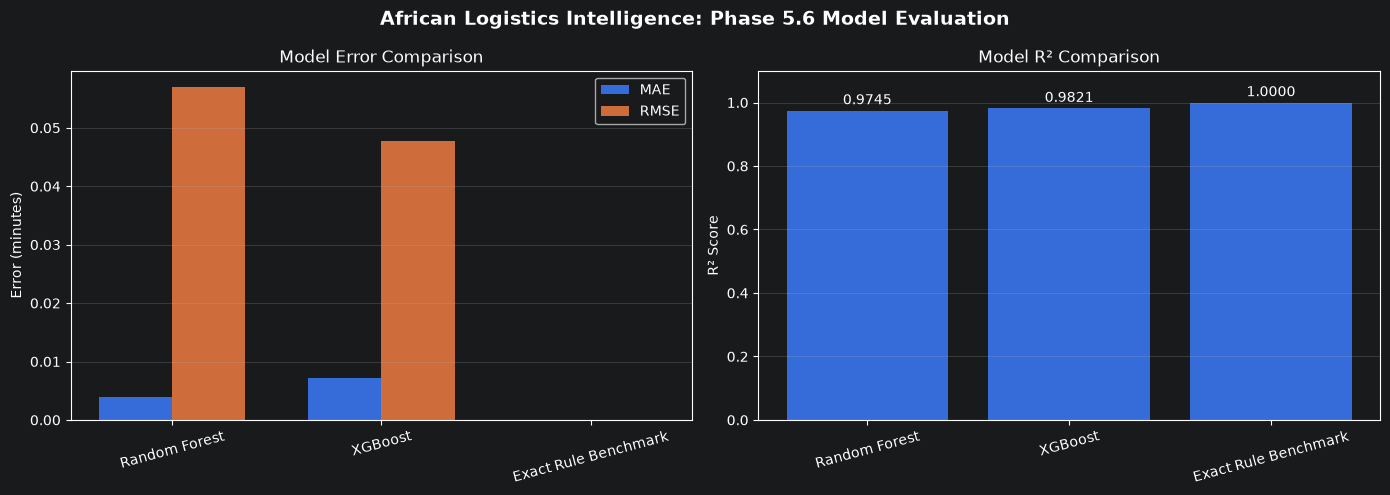

In [17]:
import matplotlib.pyplot as plt
import numpy as np

# Results from our model evaluation
models = ["Random Forest", "XGBoost", "Exact Rule Benchmark"]

mae = [0.003952, 0.007143, 0.000000]
rmse = [0.056921, 0.047797, 0.000000]
r2 = [0.974544, 0.982051, 1.000000]

x = np.arange(len(models))
width = 0.35

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Chart 1: Error metrics
axes[0].bar(x - width/2, mae, width, label="MAE")
axes[0].bar(x + width/2, rmse, width, label="RMSE")

axes[0].set_title("Model Error Comparison")
axes[0].set_ylabel("Error (minutes)")
axes[0].set_xticks(x)
axes[0].set_xticklabels(models, rotation=15)
axes[0].legend()
axes[0].grid(axis="y", alpha=0.3)

# Chart 2: R-squared
bars = axes[1].bar(models, r2)

axes[1].set_title("Model R² Comparison")
axes[1].set_ylabel("R² Score")
axes[1].set_ylim(0, 1.1)
axes[1].tick_params(axis="x", rotation=15)
axes[1].grid(axis="y", alpha=0.3)

# Add values above R² bars
for bar, score in zip(bars, r2):
    axes[1].text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 0.02,
        f"{score:.4f}",
        ha="center",
        fontsize=10
    )

plt.suptitle(
    "African Logistics Intelligence: Phase 5.6 Model Evaluation",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

## What this notebook does not yet do

- It does not use live traffic observations. TomTom did not provide usable Lagos segment data in the earlier experiment.
- The weather data comes from one representative Lagos coordinate and is repeated across sampled roads for each timestamp.
- The 5,000 sampled roads are limited to the six classes for which the project currently defines synthetic base-speed assumptions.
- The 3.6 million records are repeated road-hour scenarios, not 3.6 million independent observed journeys.
- A high R² on this dataset means the model reproduces the synthetic rule well. It does not prove accurate real-world travel-time prediction.

## PuLP or Google OR-Tools?

**Neither is required for Phase 5.6 model training.** Scikit-learn and XGBoost train the prediction models.

**Google OR-Tools belongs in the optimization stage.** Phase 4 already uses routing optimization; Phase 5.7 should supply better edge or route travel-time costs to that engine after the prediction model has been validated.

**PuLP is not needed here.** It is useful for formulating linear and mixed-integer optimization models, but it does not train a travel-time prediction model and it is not a replacement for OR-Tools in the existing vehicle-routing workflow.

## The next real-data requirement

To claim real travel-time prediction, replace the synthetic target with observed segment or trip travel times, ideally derived from GPS traces with timestamps, map-matched to the road network. Keep the synthetic dataset as a pipeline-development benchmark, not as ground truth.